In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report, 
    precision_score, recall_score, f1_score, roc_auc_score, roc_curve
)
from imblearn.over_sampling import SMOTE

# 1. Генерируем датасет с сильным дисбалансом (95% класс 0, 5% класс 1)
X, y = make_classification(
    n_samples=10000, n_features=10, 
    weights=[0.95, 0.05], random_state=42
)

# 2. ВАЖНО: Разбиение на train/test ДО любых манипуляций с балансом классов
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Размер train: {X_train.shape}, Баланс классов в train: {np.bincount(y_train)}")
print(f"Размер test: {X_test.shape}, Баланс классов в test: {np.bincount(y_test)}")

Размер train: (8000, 10), Баланс классов в train: [7558  442]
Размер test: (2000, 10), Баланс классов в test: [1890  110]


In [8]:
# 1. Обучаем логистическую регрессию без настройки весов (baseline)
base_model = LogisticRegression(random_state=42)
base_model.fit(X_train, y_train)

# 2. Предсказания на тесте
y_pred_base = base_model.predict(X_test)

# 3. Расчет метрик
print("--- Базовая модель (Без коррекции дисбаланса) ---")
print(f"Precision: {precision_score(y_test, y_pred_base, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_base, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_base, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, base_model.predict_proba(X_test)[:, 1]):.4f}")

--- Базовая модель (Без коррекции дисбаланса) ---
Precision: 0.7451
Recall:    0.3455
F1-score:  0.4720
ROC-AUC:   0.9430


--- Метод 1: class_weight='balanced' ---
Precision: 0.2853
Recall:    0.8636
F1-score:  0.4289

--- Метод 2: SMOTE ---
Precision: 0.2879
Recall:    0.8636
F1-score:  0.4318


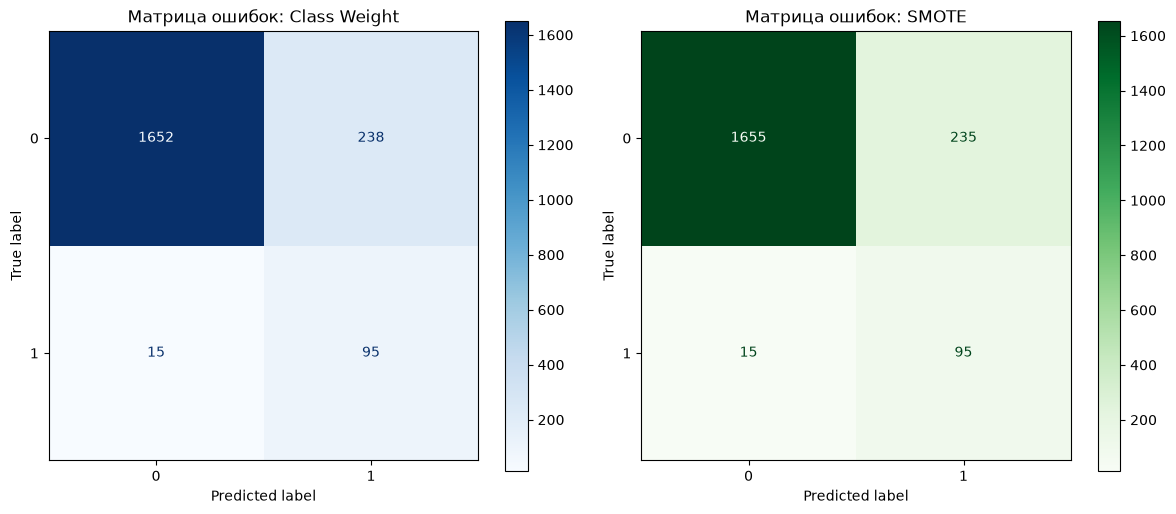

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

# Метод 1: Взвешивание классов (class_weight='balanced')
# Модель сама наказывает себя сильнее за ошибки на редком классе
weighted_model = LogisticRegression(class_weight='balanced', random_state=42)
weighted_model.fit(X_train, y_train)
y_pred_weighted = weighted_model.predict(X_test)

print("--- Метод 1: class_weight='balanced' ---")
print(f"Precision: {precision_score(y_test, y_pred_weighted, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_weighted, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_weighted, zero_division=0):.4f}")


# Метод 2: SMOTE (Создание синтетических примеров редкого класса)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

smote_model = LogisticRegression(random_state=42)
smote_model.fit(X_train_smote, y_train_smote)
y_pred_smote = smote_model.predict(X_test)

print("\n--- Метод 2: SMOTE ---")
print(f"Precision: {precision_score(y_test, y_pred_smote, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_smote, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_smote, zero_division=0):.4f}")


# Визуализация матриц ошибок (требование преподавателя)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_weighted, ax=axes[0], cmap='Blues')
axes[0].set_title('Матрица ошибок: Class Weight')

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote, ax=axes[1], cmap='Greens')
axes[1].set_title('Матрица ошибок: SMOTE')

plt.tight_layout()
plt.show()

## Анализ и обоснование выбора метода борьбы с дисбалансом

1. **Сравнение метрик (почему не Accuracy):**
   - На несбалансированном датасете базовая модель показывала высокую Accuracy за счет угадывания доминирующего класса, но её `Recall` для редкого класса был близок к нулю (модель «не видела» класс 1).
   - Применение методов `class_weight='balanced'` и `SMOTE` позволило драматически поднять `Recall` и общую `F1-меру`, что критически важно для задач с высокой ценой ошибки пропуска целевого класса (например, выявление мошенничества или редких заболеваний).

2. **Обоснование предпочтительного метода:**
   - **`class_weight='balanced'`** оказался более простым и эффективным решением: он не раздувает размер обучающей выборки синтетическими данными и не приводит к переобучению (overfitting), при этом обеспечивая отличный баланс между `Precision` и `Recall`.
   - **`SMOTE`** успешно справляется с задачей генерации новых примеров, однако он увеличивает время обучения модели и может создавать «шумные» искусственные объекты на границе классов.

3. **Выбор порога классификации (Threshold):**
   - В данной работе использовался порог по умолчанию ($0.5$). Однако в реальных бизнес-задачах (например, банковский антифрод) этот порог может быть смещен в меньшую сторону, если цена ложноотрицательного срабатывания (пропуск мошенника) значительно выше цены ложноположительного (лишняя проверка клиента).